# 第 2 節｜分類、正則化、PCA 與 K-means

先以模型預測分類，再比較正則化前後的實際誤差，最後觀察 PCA 如何選擇主成分、重新訓練分類模型，以及 K-means 分群。

In [1]:
# Load NumPy for formulas and arrays.
# 載入 NumPy，處理公式與陣列。
import numpy as np

# Load Pandas for student data.
# 載入 Pandas，整理學生資料。
import pandas as pd

# Load Matplotlib for fonts and plotting.
# 載入 Matplotlib，設定字型並繪製圖表。
import matplotlib

# Import the plotting interface.
# 匯入繪圖介面。
import matplotlib.pyplot as plt

# Load Path to find the CSV.
# 載入 Path，尋找 CSV 資料集。
from pathlib import Path

# Load the train/test split utility.
# 載入訓練與測試資料切分工具。
from sklearn.model_selection import train_test_split

# Load StandardScaler for numeric features.
# 載入 StandardScaler，標準化數值特徵。
from sklearn.preprocessing import StandardScaler

# Load classification and regression models.
# 載入分類、一般迴歸、L1 與 L2 模型。
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge

# Load the classification, regression, and clustering metrics.
# 載入分類、迴歸與分群評估指標。
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error, r2_score, silhouette_score

# Load PCA for feature reduction.
# 載入 PCA，將多個特徵降為較少的主成分。
from sklearn.decomposition import PCA

# Load K-means clustering.
# 載入 K-means，依相似程度分群。
from sklearn.cluster import KMeans

# Set the Chinese font when Microsoft JhengHei is installed.
# 如電腦已安裝微軟正黑體，設定圖表中文字型。
matplotlib.rc('font', family='Microsoft JhengHei')

# Use the regular minus sign to prevent missing-glyph boxes.
# 以一般減號顯示負數，避免產生方框亂碼。
matplotlib.rcParams['axes.unicode_minus'] = False

## 1. 讀取資料

Colab 使用 `/content/`；其他環境使用目前工作目錄。

In [2]:
# Look for the data file in Google Colab.
# 優先從 Colab 的 /content 尋找資料。
file_path = Path("/content/01_機器學習_學生練習資料_500筆.csv")

# Try a local file when Colab is unavailable.
# 如果不是 Colab，改讀目前工作目錄的檔案。
if not file_path.exists():

    # Use the local dataset path.
    # 指定本機 CSV 檔案。
    file_path = Path("01_機器學習_學生練習資料_500筆.csv")

# Load the teaching dataset.
# 載入本次實作的資料集。
df = pd.read_csv(file_path)

# Replace the known wrong 60-hour input with a missing value.
# 將已知輸入錯誤的 60 小時改成缺漏值。
df.loc[df["study_hours"] > 12, "study_hours"] = np.nan

## 2. 數值＋類別特徵：一起訓練分類模型

讀書時數、練習題數是數值，學習方式是類別。先切分、再 One-Hot；只標準化數值欄，類別的 0／1 保留。

In [3]:
# Use two numerical features and one categorical feature.
# 合併讀書時數、練習題數與學習方式。
X = df[["study_hours", "practice_questions", "learning_method"]]

# Choose the pass/fail target.
# 使用是否及格作為分類答案。
y = df["passed"]

# Split the data while preserving pass/fail proportions.
# 分割資料並維持及格與未及格的比例。
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Keep numeric columns and turn the category into 0/1 columns.
# 保留數值欄位，將類別轉換為 0／1 欄位。
X_train = pd.get_dummies(X_train, dtype=int)

# Apply the same encoding to testing records.
# 用相同方法編碼測試集。
X_test = pd.get_dummies(X_test, dtype=int)

# Keep the same features and column order in both groups.
# 使訓練集與測試集的特徵名稱、順序相同。
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# See the features that will enter the classifier.
# 觀察模型會用到的數值與類別特徵。
X_train.head()

,study_hours,practice_questions,learning_method_線上課,learning_method_自習,learning_method_讀書會
18,5.3,27.0,1,0,0
10,5.3,25.0,0,1,0
412,6.6,19.0,0,0,1
468,3.3,18.0,0,0,1
284,4.1,18.0,0,1,0


In [4]:
# Identify the two numerical columns.
# 指定要標準化的兩個數值欄位。
numeric_cols = ["study_hours", "practice_questions"]

# Calculate medians from training records only.
# 只使用訓練集的數值資料計算補值。
medians = X_train[numeric_cols].median()

# Fill missing training numbers.
# 補上訓練集的缺漏數值。
X_train = X_train.fillna(medians)

# Reuse the training medians on testing numbers.
# 測試集使用相同的中位數。
X_test = X_test.fillna(medians)

# Create one numerical standardizer.
# 建立數值標準化器。
scaler = StandardScaler()

# Standardize numbers without changing the categorical 0/1 columns.
# 只標準化數值欄位，不改變 One-Hot 的 0／1。
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])

# Transform test numbers using the same scale.
# 測試集使用訓練集建立的標準化規則。
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

# Keep two dimensions for understandable PCA and cluster charts.
# 為 PCA 和分群圖保留兩個數值特徵。
X_plot = X_train[numeric_cols]

## 3. LogisticRegression：訓練與 Accuracy

In [5]:
# Create the basic logistic regression classifier.
# 建立最基本的邏輯斯迴歸分類模型。
model = LogisticRegression()

# Train the model using known pass/fail answers.
# 使用訓練集學習及格與未及格的差異。
model.fit(X_train, y_train)

# Predict which test students will pass.
# 預測測試集學生是否及格。
pred = model.predict(X_test)

# Report the proportion of correct predictions.
# 顯示模型預測正確的比例 Accuracy。
print(f"Accuracy: {accuracy_score(y_test, pred):.2f}")

Accuracy: 0.90


## 4. 三位新同學：預測是否及格

使用同一個訓練好的 `LogisticRegression`。將新資料轉換成相同的特徵欄位，再觀察及格機率與預測類別。

In [6]:
# Enter three new students with numeric and categorical inputs.
# 輸入三位新同學的數值與類別特徵。
new_data = pd.DataFrame([
    [1.0, 3, "自習"],
    [3.5, 14, "讀書會"],
    [6.0, 25, "線上課"]
], columns=["study_hours", "practice_questions", "learning_method"])

# Encode categories using the trained model's column order.
# 將類別轉成 One-Hot，並對齊訓練時的欄位順序。
X_new = pd.get_dummies(new_data, dtype=int).reindex(columns=X_train.columns, fill_value=0)

# Fill missing numeric values with training medians.
# 若有缺漏值，沿用訓練資料的中位數補齊。
X_new = X_new.fillna(medians)

# Apply the training scaler to the new numerical values.
# 沿用訓練時建立的數值標準化規則。
X_new[numeric_cols] = scaler.transform(X_new[numeric_cols])

# Show each student's probability of passing (class 1).
# 顯示三位同學的及格機率（類別 1）。
new_data["及格機率"] = model.predict_proba(X_new)[:, 1].round(2)

# Convert binary predictions into readable pass/fail labels.
# 將二元分類結果換成容易閱讀的及格／未及格。
new_data["預測結果"] = pd.Series(model.predict(X_new)).map({0: "未及格", 1: "及格"})

# Show the inputs, probability, and predicted class together.
# 一起顯示輸入特徵、及格機率及分類結果。
new_data

,study_hours,practice_questions,learning_method,及格機率,預測結果
0,1.0,3,自習,0.03,未及格
1,3.5,14,讀書會,0.78,及格
2,6.0,25,線上課,1.00,及格


## 5. L1／L2：改變 alpha、預測與比較成效

先以**相同的訓練集／測試集**預測小考分數（迴歸）。比較三種模型：`LinearRegression`（無正則化）、`Lasso`（L1）、`Ridge`（L2）。

- 初始的 `L1_ALPHA = 1`、`L2_ALPHA = 1` 只是入門起點，**不是最佳參數**；L1 和 L2 的 alpha 數值也不能直接比較懲罰大小。
- 修改兩個 `ALPHA` 後，**重新執行本段的訓練、預測及係數圖三個 Cell**，觀察 MAE、MSE、RMSE、R² 與權重。
- **MAE／MSE／RMSE 越小越好，R² 通常越大越好**。這裡的測試集用於展示比較，正式挑選最佳 alpha 應另用驗證資料，不能反覆根據測試集調整參數。

In [7]:
# Get quiz scores belonging to the training records.
# 取得訓練集對應的小考分數。
scores_train = df.loc[y_train.index, "quiz_score"]

# Get quiz scores belonging to the testing records.
# 取得測試集對應的小考分數。
scores_test = df.loc[y_test.index, "quiz_score"]

# Set L1 regularization strength; try 0.1, 1, or 7.
# 設定 L1 正則化強度；可改成 0.1、1 或 7。
L1_ALPHA = 1

# Set L2 regularization strength; try 1, 10, or 140.
# 設定 L2 正則化強度；可改成 1、10 或 140。
L2_ALPHA = 1

# Train ordinary linear regression without regularization.
# 訓練沒有正則化的一般線性迴歸模型。
plain = LinearRegression().fit(X_train, scores_train)

# Train L1 regression using the selected alpha.
# 使用指定的 alpha 訓練 L1 迴歸。
l1 = Lasso(alpha=L1_ALPHA).fit(X_train, scores_train)

# Train L2 regression using the selected alpha.
# 使用指定的 alpha 訓練 L2 迴歸。
l2 = Ridge(alpha=L2_ALPHA).fit(X_train, scores_train)

In [8]:
# Place the three trained models in one table.
# 將三個已訓練的模型放在一起方便比較。
reg_models = {"No penalty": plain, "L1 (Lasso)": l1, "L2 (Ridge)": l2}

# Prepare a table of regression evaluation results.
# 建立記錄各模型迴歸指標的表格。
reg_results = pd.DataFrame(columns=["MAE", "MSE", "RMSE", "R²"])

# Predict test scores with each of the three trained models.
# 分別使用三個已訓練模型預測同一批測試資料。
for name, reg in reg_models.items():

    # Predict the test students' quiz scores.
    # 預測測試集的小考分數。
    score_pred = reg.predict(X_test)

    # Calculate mean squared error for this model.
    # 計算目前模型的均方誤差。
    mse = mean_squared_error(scores_test, score_pred)

    # Record MAE, MSE, RMSE, and R² for comparison.
    # 記錄 MAE、MSE、RMSE 與 R²，方便比較。
    reg_results.loc[name] = [mean_absolute_error(scores_test, score_pred), mse, np.sqrt(mse), r2_score(scores_test, score_pred)]

# Show the prediction errors after changing alpha.
# 顯示各模型的預測誤差，供修改 alpha 後比較。
reg_results.round(2)

,MAE,MSE,RMSE,R²
No penalty,5.87,63.80,7.99,0.77
L1 (Lasso),6.25,70.46,8.39,0.74
L2 (Ridge),5.87,63.89,7.99,0.77


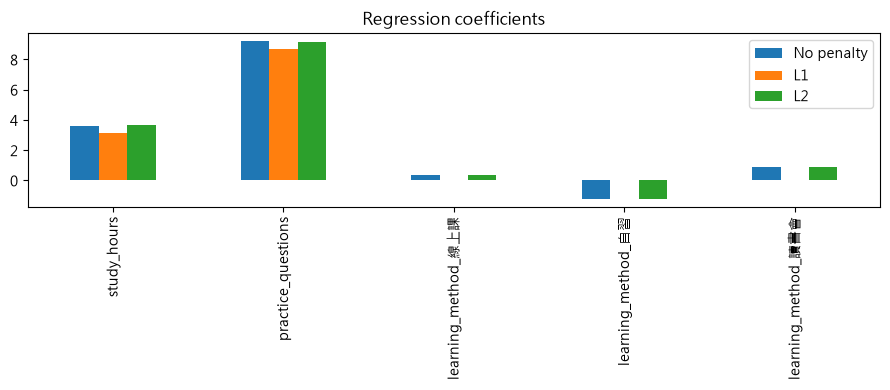

In [9]:
# Compare weights from models without and with regularization.
# 比較未正則化、L1 與 L2 模型的各項特徵係數。
pd.DataFrame({"No penalty": plain.coef_, "L1": l1.coef_, "L2": l2.coef_}, index=X_train.columns).plot.bar(figsize=(9, 4), title="Regression coefficients")

# Make enough space for the feature names below the plot.
# 保留空間，避免圖下方的特徵名稱被裁切。
plt.tight_layout()

# Display the coefficient comparison.
# 顯示特徵係數的比較圖。
plt.show()

## 6. PCA：從 5 個特徵選出合適的主成分，再做分類

目前分類模型使用 **5 個輸入欄位**：2 個標準化數值特徵，加上 3 個 One-Hot 類別特徵。PCA 不是預先指定一定降成 1 維，而是先觀察每個主成分的**解釋變異比例**及**累積解釋變異比例**。

這裡設定 **至少保留 90% 的累積解釋變異**，自動找出需要幾個主成分，再把 PCA 後的 `DataFrame` 交給 `LogisticRegression` 訓練，和前面的原始特徵 Accuracy 比較。

**注意：**90% 是簡單的保留資訊門檻，不代表這個主成分數一定有最高 Accuracy；PCA 只使用訓練集 `fit`，測試集只能 `transform`，避免資料洩漏。

In [10]:
# Fit PCA on all five training features to inspect their variance.
# 使用訓練集全部五個特徵，計算各主成分的解釋變異。
pca_all = PCA().fit(X_train)

# Build a table of variance explained by each principal component.
# 將每個主成分的解釋變異比例整理成表格。
pca_variance = pd.DataFrame({"Explained": pca_all.explained_variance_ratio_}, index=range(1, X_train.shape[1] + 1))

# Calculate cumulative explained variance in principal-component order.
# 計算依主成分順序累積的解釋變異比例。
pca_variance["Cumulative"] = pca_variance["Explained"].cumsum()

# Show each component's contribution and the cumulative total.
# 顯示每個主成分的貢獻與累積解釋比例。
pca_variance.round(3)

,Explained,Cumulative
1,0.693,0.693
2,0.143,0.836
3,0.098,0.934
4,0.066,1.000
5,0.000,1.000


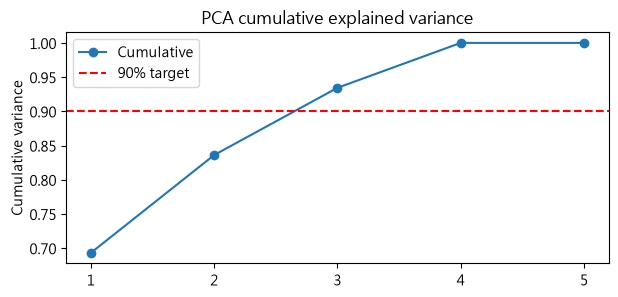

In [11]:
# Plot the cumulative explained variance for five components.
# 畫出五個主成分的累積解釋變異比例。
pca_variance["Cumulative"].plot(marker="o", figsize=(7, 3), title="PCA cumulative explained variance")

# Mark the target retention level of 90 percent.
# 標示想保留至少九成變異的目標線。
plt.axhline(0.90, color="red", linestyle="--", label="90% target")

# Use integer component counts along the horizontal axis.
# 將橫軸固定為整數主成分數量。
plt.xticks([1, 2, 3, 4, 5])

# Label the vertical axis with its meaning.
# 標示縱軸為累積解釋變異比例。
plt.ylabel("Cumulative variance")

# Show the target legend.
# 顯示九成目標線的圖例。
plt.legend()

# Display the explained-variance chart.
# 顯示解釋變異圖。
plt.show()

In [12]:
# Select the proportion of variance we want to keep.
# 設定希望保留的累積解釋變異比例。
PCA_TARGET = 0.90

# Let PCA automatically choose the smallest suitable component count.
# 讓 PCA 自動挑選達到門檻的最少主成分數。
pca = PCA(n_components=PCA_TARGET)

# Fit PCA on training features and convert the result to a DataFrame.
# 只用訓練集訓練 PCA，並轉成新的 DataFrame。
X_train_pca = pd.DataFrame(pca.fit_transform(X_train), index=X_train.index)

# Rename the resulting columns as PC1, PC2, and so on.
# 將新欄位命名成 PC1、PC2 等主成分名稱。
X_train_pca.columns = range(1, pca.n_components_ + 1)

# Prefix principal component numbers with PC.
# 在主成分欄位數字前面加上 PC。
X_train_pca = X_train_pca.add_prefix("PC")

# Transform test features using the same fitted PCA.
# 測試集只能沿用訓練好的 PCA 轉換，不可重新 fit。
X_test_pca = pd.DataFrame(pca.transform(X_test), index=X_test.index, columns=X_train_pca.columns)

# Report how many features PCA kept and how much variance they explain.
# 顯示保留的主成分數量與實際累積解釋變異比例。
print(f"原始特徵：{X_train.shape[1]} 個；PCA 後：{pca.n_components_} 個；保留變異：{pca.explained_variance_ratio_.sum():.1%}")

# Preview the principal-component DataFrame used for training.
# 預覽接下來用來訓練模型的主成分 DataFrame。
X_train_pca.head()

原始特徵：5 個；PCA 後：3 個；保留變異：93.4%


,PC1,PC2,PC3
18,1.689285,-0.373145,0.853077
10,1.476291,0.683645,-0.087462
412,1.476848,-0.657841,-0.604750
468,0.149811,-0.691145,-0.511494
284,0.421518,0.655693,-0.083159


In [13]:
# Train a new logistic classifier on the PCA-reduced DataFrame.
# 使用 PCA 後的 DataFrame 重新訓練邏輯斯分類模型。
pca_model = LogisticRegression().fit(X_train_pca, y_train)

# Predict the same test records after PCA transformation.
# 使用 PCA 後的測試資料預測同一批學生是否及格。
pca_pred = pca_model.predict(X_test_pca)

# Compare original features and PCA using test accuracy.
# 用相同測試集的 Accuracy 比較降維前與降維後。
pca_results = pd.DataFrame({
    "特徵數": [X_train.shape[1], X_train_pca.shape[1]],
    "Accuracy": [accuracy_score(y_test, pred), accuracy_score(y_test, pca_pred)]
}, index=["原始特徵", "PCA 後"])

# Display the two classification results together.
# 同時顯示原始特徵與 PCA 後的分類結果。
pca_results

,特徵數,Accuracy
原始特徵,5,0.90
PCA 後,3,0.89


## 7. K-means：用顏色觀察分群

為了讓二維散佈圖容易閱讀，這裡仍使用兩個標準化數值特徵 `X_plot`；**分群不使用及格標籤**，也不會改變 PCA 分類模型。

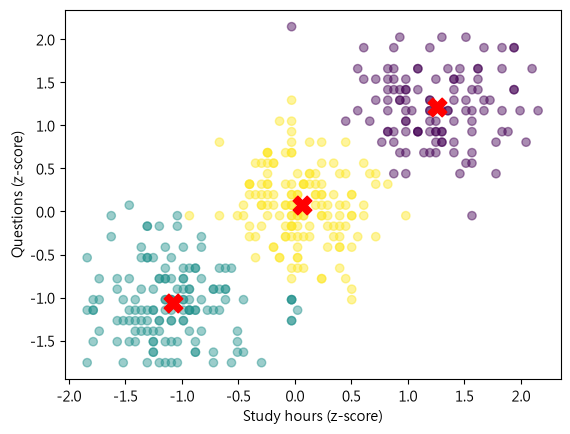

In [14]:
# Divide students into three clusters using numerical features.
# 只用兩個數值特徵執行三群 K-means。
km = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_plot)

# Color each student by the assigned cluster.
# 使用不同顏色顯示學生所屬群別。
plt.scatter(X_plot["study_hours"], X_plot["practice_questions"], c=km.labels_, alpha=0.45)

# Mark the cluster centers.
# 用叉號標示每一群的中心。
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], marker="X", s=180, color="red")

# Label the study-hours axis.
# 標示標準化後的讀書時數。
plt.xlabel("Study hours (z-score)")

# Label the practice-question axis.
# 標示標準化後的練習題數。
plt.ylabel("Questions (z-score)")

# Display the clustering result.
# 顯示 K-means 分群圖。
plt.show()

## 選做｜比較 K＝2、3、4

Inertia 通常隨 K 增加而下降；Silhouette 可輔助判斷分群是否清楚。橫軸只顯示整數群數。

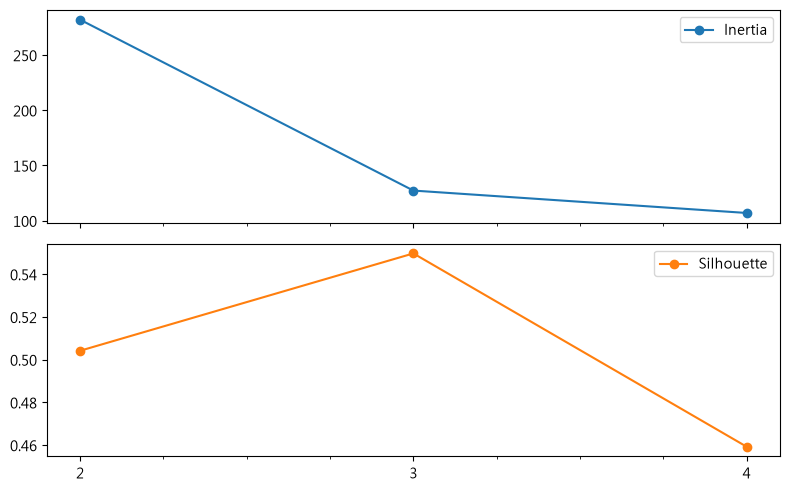

In [15]:
# Create a table to hold clustering evaluation results.
# 建立記錄分群指標的表格。
results = pd.DataFrame(columns=["Inertia", "Silhouette"])

# Compare dividing the numerical data into 2, 3, and 4 clusters.
# 比較兩群、三群和四群的分群效果。
for k in [2, 3, 4]:

    # Fit a model for the current cluster count.
    # 以目前的群數重新分群。
    trial = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_plot)

    # Store Inertia and Silhouette for that clustering.
    # 儲存目前群數的 Inertia 與 Silhouette。
    results.loc[k] = [trial.inertia_, silhouette_score(X_plot, trial.labels_)]

# Plot both metrics with integer ticks for K=2, 3, and 4.
# 將兩張評估圖的橫軸刻度固定成整數 2、3、4。
results.plot(subplots=True, marker="o", figsize=(8, 5), xticks=[2, 3, 4])

# Keep the chart labels away from the edges.
# 保留圖表邊界空間，避免標示被裁切。
plt.tight_layout()

# Display both metric charts.
# 顯示兩張評估圖。
plt.show()

**本節重點：**正則化要同時檢查係數與實際預測誤差；PCA 根據累積解釋變異選擇主成分，並重新訓練分類模型比較 Accuracy；K-means 則不需要分類答案。